# Lab I002 — *Deep Inside Convolutional Networks*: class models and saliency maps

**Paper:** Karen Simonyan, Andrea Vedaldi, Andrew Zisserman (2013). [arXiv:1312.6034](https://arxiv.org/abs/1312.6034)

## 1. The paper's core claim

A ConvNet's class score can be probed by taking its gradient with respect to the input image.
First, starting from a blank (mean-centred) image, gradient ascent with L2 regularisation finds an image that maximises a chosen class's unnormalised score — a picture of what the model has learned about that class.
Second, at a real image, the same gradient from a single backward pass becomes an image-specific saliency map: the maximum absolute value over the colour channels shows which pixels matter for that class.
Both methods use the raw class score, not the softmax probability, so the procedure cannot "cheat" by suppressing other classes.

## What this lab does

| Section | What you get |
|---|---|
| 2. Setup & data | Downloads Imagenette validation images and loads pretrained torchvision VGG-16 |
| 3. Reproduction | First, class model visualisation for a few ImageNet classes. Then, saliency maps on a handful of images. Each part ends with one plot |
| 4. Twist | To be decided |
| 5. Your findings | Prompts for you to write up what you saw |
| 6. Further ideas | Where to go next |

**Important differences from the paper.** The paper used a ConvNet trained on ILSVRC-2013. This lab uses pretrained VGG-16, the closest widely available relative, and a handful of Imagenette validation images instead of the full ImageNet test set. Saliency is computed on one centre crop, not averaged over the paper's 10 crops. The goal is to reproduce the *shape* of the results (recognisable class images; saliency that lights up the object), not to match their figures pixel for pixel.


## 2. Setup & data

### 2.1 Configuration
`QUICK_MODE = True` runs the whole notebook fast with fewer ascent steps, classes and images (good for checking that everything works). Set it to `False` for the full run, which takes longer.


In [1]:
# ---------------- configuration ----------------
import torch

QUICK_MODE = False          # True: fast check run, False: full lab
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
IMAGE_SIZE = 224           # VGG-16 input size

# ImageNet class indices to visualise. Names are looked up from the model weights.
if QUICK_MODE:
    VIS_CLASSES   = [1, 130, 251, 546]                # goldfish, flamingo, dalmatian, electric guitar
    VIS_STEPS     = 80
    VIS_STEP_SIZE = 1.0
    VIS_L2        = 1e-4                              # lambda in S_c(I) - lambda ||I||^2
    N_SALIENCY    = 3                                 # number of Imagenette val images
else:
    VIS_CLASSES   = [1, 130, 251, 366, 546, 980]      # goldfish, flamingo, dalmatian, gorilla, electric guitar, volcano
    VIS_STEPS     = 300
    VIS_STEP_SIZE = 1.0
    VIS_L2        = 1e-4
    N_SALIENCY    = 8

# Twist (section 4): GPT-2 small text saliency for gender bias
TWIST_MODEL = "gpt2"
TWIST_OCC_CANDIDATES = [
    "nurse", "engineer", "secretary", "carpenter", "librarian", "surgeon",
    "doctor", "teacher", "lawyer", "pilot", "chef", "baker", "farmer",
    "painter", "mechanic", "accountant", "banker", "clerk", "manager",
    "director", "scientist", "physicist", "chemist", "biologist", "programmer",
    "developer", "architect", "designer", "writer", "journalist", "musician",
    "actor", "actress", "athlete", "coach", "soldier", "officer", "firefighter",
    "dentist", "psychologist", "therapist", "professor", "bartender", "waiter",
    "maid", "driver", "judge", "politician", "economist", "historian",
    "philosopher", "analyst", "consultant", "entrepreneur", "investor",
    "detective", "reporter", "editor", "photographer", "dancer", "singer",
    "priest", "technician", "assistant",
]
TWIST_TEMPLATES_ALL = [
    "The {occ} said that",
    "The {occ} went home because",
    "The {occ} told the client that",
]
TWIST_N_OCC = 10 if QUICK_MODE else 50
TWIST_N_TEMPLATES = 1 if QUICK_MODE else 3

print(f"QUICK_MODE={QUICK_MODE}, device={DEVICE}, vis_classes={VIS_CLASSES}, vis_steps={VIS_STEPS}, n_saliency={N_SALIENCY}")
print(f"twist: model={TWIST_MODEL}, n_occ={TWIST_N_OCC}, n_templates={TWIST_N_TEMPLATES}")


QUICK_MODE=False, device=cuda, vis_classes=[1, 130, 251, 366, 546, 980], vis_steps=300, n_saliency=8
twist: model=gpt2, n_occ=50, n_templates=3


In [2]:
import random, tarfile, urllib.request, platform
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torchvision
from torchvision.models import vgg16, VGG16_Weights
from torchvision.transforms import InterpolationMode
import torchvision.transforms as T

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DATA_DIR = Path("data");     DATA_DIR.mkdir(exist_ok=True)
OUT_DIR = Path("outputs");   OUT_DIR.mkdir(exist_ok=True)

# ImageNet normalisation used by the VGG-16 weights
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
IMAGENET_STD  = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)

print(f"python {platform.python_version()} | torch {torch.__version__} | torchvision {torchvision.__version__}")
print(f"device: {DEVICE}")


python 3.11.9 | torch 2.14.1+cu130 | torchvision 0.29.1+cu130
device: cuda


### 2.2 Download Imagenette

Imagenette is a 10-class subset of ImageNet. The archive is stored under `data/` and skipped if it is already there.


In [3]:
IMAGENETTE_URL = "https://s3.amazonaws.com/fast-ai-imageclas/imagenette2-320.tgz"

# WordNet ids in Imagenette -> ImageNet class index (for the 1000-way VGG-16)
IMAGENETTE = {
    "n01440764": 0,    # tench
    "n02102040": 217,  # English springer
    "n02979186": 482,  # cassette player
    "n03000684": 491,  # chain saw
    "n03028079": 497,  # church
    "n03394916": 566,  # French horn
    "n03417042": 569,  # garbage truck
    "n03425413": 571,  # gas pump
    "n03445777": 574,  # golf ball
    "n03888257": 701,  # parachute
}


def download(url, dest):
    """Download url -> dest (skips if the file exists)."""
    dest = Path(dest)
    if dest.exists() and dest.stat().st_size > 0:
        return dest
    print(f"downloading {url} ...")
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 paper-labs"})
    with urllib.request.urlopen(req, timeout=300) as r, open(dest, "wb") as f:
        while chunk := r.read(1 << 20):
            f.write(chunk)
    return dest


ARCHIVE = DATA_DIR / "imagenette2-320.tgz"
VAL_DIR = DATA_DIR / "imagenette2-320" / "val"

if not VAL_DIR.exists():
    download(IMAGENETTE_URL, ARCHIVE)
    print("extracting ...")
    with tarfile.open(ARCHIVE, "r:gz") as tar:
        tar.extractall(DATA_DIR, filter="data")

n_val = sum(1 for _ in VAL_DIR.glob("*/*.JPEG"))
print(f"{VAL_DIR}: {n_val} validation images")


data\imagenette2-320\val: 3925 validation images


### 2.3 Load pretrained VGG-16

The weights are the standard ImageNet-1k checkpoint from torchvision. The model is set to eval mode and its parameters are frozen: we only differentiate with respect to the input.


In [4]:
weights = VGG16_Weights.IMAGENET1K_V1
model = vgg16(weights=weights).to(DEVICE).eval()
for p in model.parameters():
    p.requires_grad_(False)

CLASS_NAMES = weights.meta["categories"]

# Resize to 256, centre-crop to 224, then ToTensor — normalisation is applied separately
to_input = T.Compose([
    T.Resize(256, interpolation=InterpolationMode.BILINEAR, antialias=True),
    T.CenterCrop(IMAGE_SIZE),
    T.ToTensor(),
])

print("loaded VGG-16 (IMAGENET1K_V1)")
print("classes to visualise:", [f"{i}: {CLASS_NAMES[i]}" for i in VIS_CLASSES])


loaded VGG-16 (IMAGENET1K_V1)
classes to visualise: ['1: goldfish', '130: flamingo', '251: dalmatian', '366: gorilla', '546: electric guitar', '980: volcano']


## 3. Minimal reproduction

### 3.1 Class model visualisation

The paper finds an image $I$ that maximises the unnormalised class score minus an L2 penalty:

$$I^* = \arg\max_I\, S_c(I) - \lambda \|I\|_2^2$$

They start from a zero image in mean-centred space and climb the gradient of $S_c$ with respect to $I$, with the network weights held fixed. After the ascent we add the ImageNet mean back for display.

VGG-16 also divides by the ImageNet standard deviation, so the forward pass is `(centred / std)`. That is the only extra bookkeeping needed to use these weights.


visualising 1: goldfish ...
visualising 130: flamingo ...
visualising 251: dalmatian ...
visualising 366: gorilla ...
visualising 546: electric guitar ...
visualising 980: volcano ...


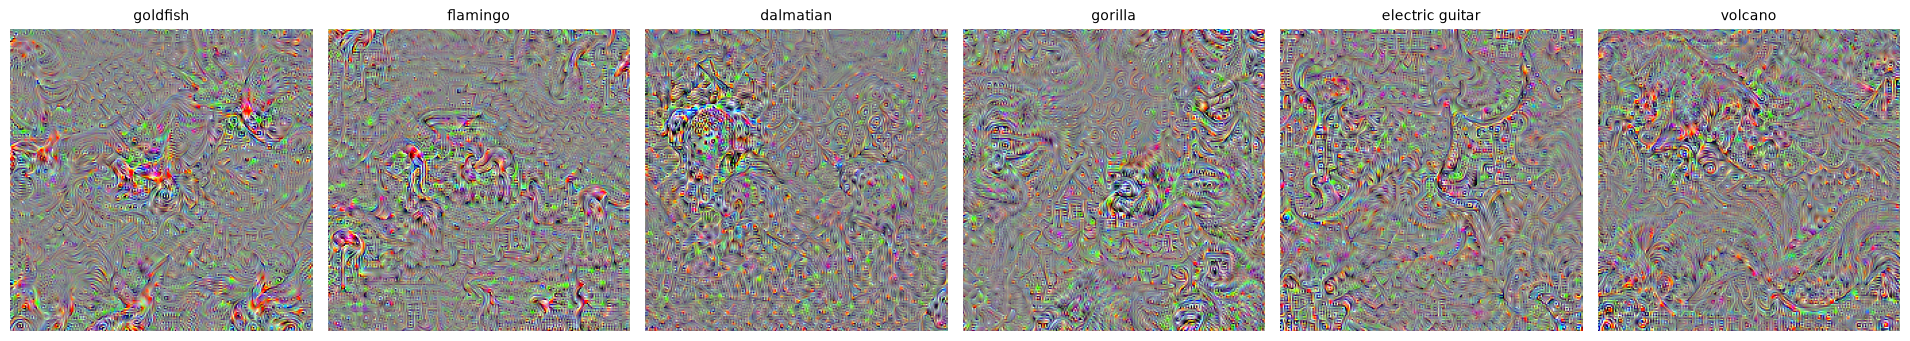

In [5]:
def class_model(class_idx, steps=VIS_STEPS, step_size=VIS_STEP_SIZE, l2=VIS_L2):
    """Gradient ascent on a mean-centred image to maximise class `class_idx`."""
    centred = torch.zeros(1, 3, IMAGE_SIZE, IMAGE_SIZE, device=DEVICE, requires_grad=True)
    for _ in range(steps):
        score = model(centred / IMAGENET_STD)[0, class_idx]
        (score - l2 * centred.pow(2).sum()).backward()
        with torch.no_grad():
            centred += step_size * centred.grad
            centred.grad.zero_()
    return (centred.detach() + IMAGENET_MEAN).squeeze(0)


def to_display(t):
    """Turn a (3, H, W) tensor into an (H, W, 3) array in [0, 1] for plotting."""
    x = t.detach().cpu()
    lo, hi = np.percentile(x.numpy(), (1, 99))
    x = (x - lo) / (hi - lo + 1e-8)
    return x.clamp(0, 1).permute(1, 2, 0).numpy()


images = []
for idx in VIS_CLASSES:
    print(f"visualising {idx}: {CLASS_NAMES[idx]} ...")
    images.append(class_model(idx))

n = len(images)
fig, axes = plt.subplots(1, n, figsize=(3.2 * n, 3.4))
if n == 1:
    axes = [axes]
for ax, img, idx in zip(axes, images, VIS_CLASSES):
    ax.imshow(to_display(img))
    ax.set_title(CLASS_NAMES[idx], fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.savefig(OUT_DIR / "class_models.png", dpi=120)
plt.show()


A successful reproduction looks like each image showing a class-typical texture or object shape (for example fins and orange scales for goldfish), not uniform noise or a blank field.


### 3.2 Image-specific class saliency maps

For a real image $I_0$ and a class $c$, one backward pass gives $w = \partial S_c / \partial I$ at $I_0$. The saliency map is the maximum absolute value of $w$ over the three colour channels:

$$M_{ij} = \max_c\, |w_{h(i,j,c)}|$$

This lab uses the model's top-1 predicted class, as in the paper's Figure 2.


n03425413_23251.JPEG: true=gas pump  pred=gas pump  score=8.81
n03000684_26780.JPEG: true=chain saw  pred=chain saw  score=27.77
n02979186_10230.JPEG: true=cassette player  pred=tape player  score=17.80
n03445777_10042.JPEG: true=golf ball  pred=golf ball  score=13.23
n03394916_22791.JPEG: true=French horn  pred=French horn  score=17.64
n03417042_18590.JPEG: true=garbage truck  pred=garbage truck  score=19.67
n03888257_19531.JPEG: true=parachute  pred=parachute  score=17.67
n03028079_35911.JPEG: true=church  pred=church  score=14.59


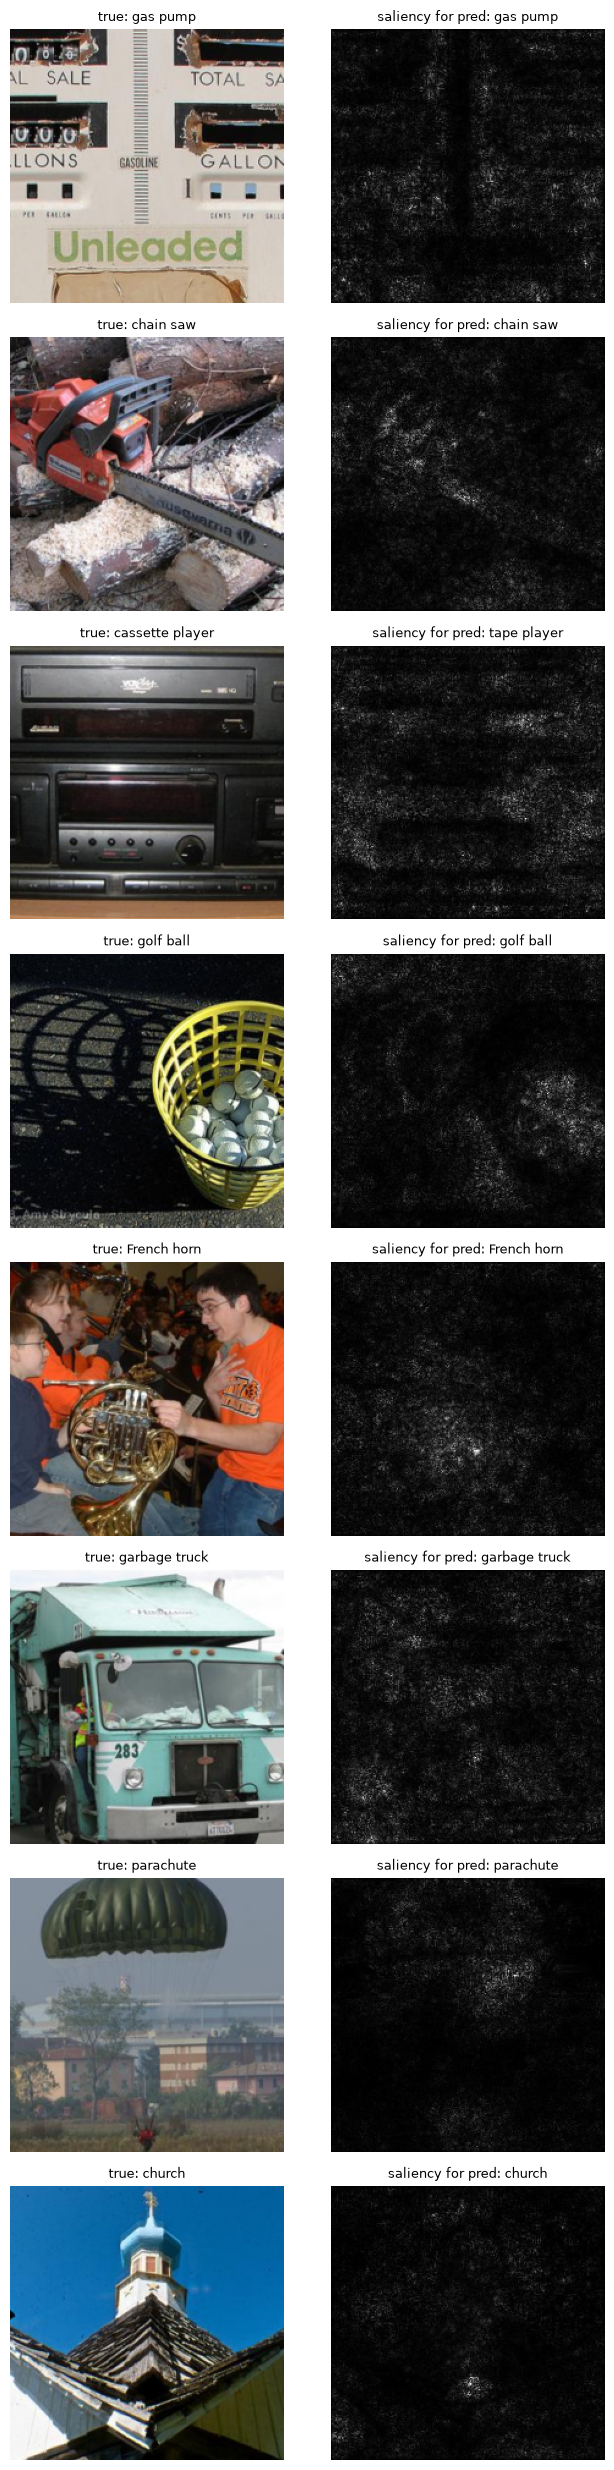

In [6]:
def saliency_map(image_01, class_idx):
    """Saliency of `class_idx` for a (3, H, W) image in [0, 1]. Returns an (H, W) map."""
    x = ((image_01.to(DEVICE) - IMAGENET_MEAN) / IMAGENET_STD).detach().requires_grad_(True)
    score = model(x)[0, class_idx]
    score.backward()
    return x.grad[0].abs().max(0).values.detach().cpu()


# One validation image from each of N_SALIENCY Imagenette classes, chosen with the fixed seed
rng = random.Random(SEED)
wnids = list(IMAGENETTE.keys())
rng.shuffle(wnids)
samples = []
for wnid in wnids[:N_SALIENCY]:
    files = sorted((VAL_DIR / wnid).glob("*.JPEG"))
    samples.append((rng.choice(files), IMAGENETTE[wnid]))

rows = []
for path, true_idx in samples:
    image_01 = to_input(Image.open(path).convert("RGB"))
    with torch.no_grad():
        logits = model(((image_01.to(DEVICE) - IMAGENET_MEAN) / IMAGENET_STD))
        pred_idx = int(logits[0].argmax())
        pred_score = float(logits[0, pred_idx])
    sal = saliency_map(image_01, pred_idx)
    rows.append((image_01, sal, true_idx, pred_idx, pred_score, path.name))
    print(f"{path.name}: true={CLASS_NAMES[true_idx]}  pred={CLASS_NAMES[pred_idx]}  score={pred_score:.2f}")

n = len(rows)
fig, axes = plt.subplots(n, 2, figsize=(7, 3.1 * n))
if n == 1:
    axes = np.array([axes])
for i, (image_01, sal, true_idx, pred_idx, pred_score, name) in enumerate(rows):
    axes[i, 0].imshow(image_01.permute(1, 2, 0).numpy())
    axes[i, 0].set_title(f"true: {CLASS_NAMES[true_idx]}", fontsize=9)
    axes[i, 0].axis("off")
    axes[i, 1].imshow(sal.numpy(), cmap="gray")
    axes[i, 1].set_title(f"saliency for pred: {CLASS_NAMES[pred_idx]}", fontsize=9)
    axes[i, 1].axis("off")
plt.tight_layout()
plt.savefig(OUT_DIR / "saliency_maps.png", dpi=120)
plt.show()


A successful reproduction looks like the saliency map lighting up the object, not the background.


## 4. Twist — GPT-2 text saliency for gender bias

The paper's saliency idea is: take the gradient of an *unnormalised* class score with respect to the input, and read off which input parts matter.
Here we apply that to **GPT-2 small**, with score = logit(` he`) − logit(` she`) after a short occupation prompt — a text analogue of the image class score.

Two checks:
- **Twist A.** Token saliency (L2 gradient, and gradient × input) plus a faithfulness swap of the occupation for ` person`.
- **Twist B.** Compare that with a static gender direction in the input embedding matrix.


### 4.0 Setup: GPT-2, occupations, templates

Load GPT-2 small, keep only occupations that are a **single** GPT-2 token with a leading space, then take `TWIST_N_OCC` / `TWIST_N_TEMPLATES` from the config.


In [7]:
from transformers import GPT2LMHeadModel, GPT2TokenizerFast
import pandas as pd
from scipy.stats import spearmanr

torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

tokenizer = GPT2TokenizerFast.from_pretrained(TWIST_MODEL)
gpt2 = GPT2LMHeadModel.from_pretrained(TWIST_MODEL).to(DEVICE).eval()
for p in gpt2.parameters():
    p.requires_grad_(False)

HE_ID = tokenizer.encode(" he", add_special_tokens=False)[0]
SHE_ID = tokenizer.encode(" she", add_special_tokens=False)[0]
PERSON = "person"

kept, dropped = [], []
for occ in TWIST_OCC_CANDIDATES:
    ids = tokenizer.encode(" " + occ, add_special_tokens=False)
    (kept if len(ids) == 1 else dropped).append(occ)
if dropped:
    print("dropped (not a single leading-space token):", ", ".join(dropped))

occupations = kept[:TWIST_N_OCC]
templates = TWIST_TEMPLATES_ALL[:TWIST_N_TEMPLATES]
print(f"kept {len(occupations)} occupations, {len(templates)} templates")
print("occupations:", ", ".join(occupations))
print("templates:", templates)


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

d:\university\HPI\Thesis\Literature_Review_Labs\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Farzad\.cache\huggingface\hub\models--gpt2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
d:\university\HPI\Thesis\Literature_Review_Labs\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: 

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

dropped (not a single leading-space token): carpenter, librarian
kept 50 occupations, 3 templates
occupations: nurse, engineer, secretary, surgeon, doctor, teacher, lawyer, pilot, chef, baker, farmer, painter, mechanic, accountant, banker, clerk, manager, director, scientist, physicist, chemist, biologist, programmer, developer, architect, designer, writer, journalist, musician, actor, actress, athlete, coach, soldier, officer, firefighter, dentist, psychologist, therapist, professor, bartender, waiter, maid, driver, judge, politician, economist, historian, philosopher, analyst
templates: ['The {occ} said that', 'The {occ} went home because', 'The {occ} told the client that']


### Twist A — text saliency for gender bias

For each occupation and template:
1. Score = logit(` he`) − logit(` she`) for the next token (unnormalised, like the paper).
2. Backprop that score through `inputs_embeds` and take per-token saliency two ways: **L2** of the gradient, and **gradient × input** (summed over the embedding dim).
3. Attribution share of the occupation token = |saliency_occ| / sum_t |saliency_t|.
4. Faithfulness: swap the occupation for ` person` and record gap_occ − gap_person.

Then Spearman-correlate attribution share with |gap change| across occupations, for both saliency variants.


In [8]:
def he_she_gap(prompt: str) -> float:
    """Next-token logit(he) - logit(she) for a prompt string."""
    ids = tokenizer.encode(prompt, return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        logits = gpt2(ids).logits[0, -1]
    return float(logits[HE_ID] - logits[SHE_ID])


def gap_and_saliency(prompt: str):
    """Return (gap, sal_l2, sal_gi, input_ids) with grads w.r.t. input embeddings."""
    input_ids = tokenizer.encode(prompt, return_tensors="pt").to(DEVICE)
    embeds = gpt2.transformer.wte(input_ids).detach().requires_grad_(True)
    logits = gpt2(inputs_embeds=embeds).logits[0, -1]
    score = logits[HE_ID] - logits[SHE_ID]
    gpt2.zero_grad(set_to_none=True)
    score.backward()
    g = embeds.grad[0]                       # (T, H)
    x = embeds.detach()[0]
    sal_l2 = g.norm(dim=-1).cpu()            # paper-style L2
    sal_gi = (g * x).sum(dim=-1).cpu()       # gradient x input
    return float(score.detach()), sal_l2, sal_gi, input_ids[0].cpu()


def occ_index(prompt: str, occ: str) -> int:
    occ_id = tokenizer.encode(" " + occ, add_special_tokens=False)[0]
    ids = tokenizer.encode(prompt, add_special_tokens=False)
    return ids.index(occ_id)


def attr_share(sal, idx: int) -> float:
    abs_sal = sal.abs()
    return float(abs_sal[idx] / abs_sal.sum().clamp_min(1e-12))


rows_a = []
example_sals = []  # (prompt, gap, tokens, sal_l2) for heatmap later

for occ in occupations:
    for tmpl in templates:
        prompt = tmpl.format(occ=occ)
        gap, sal_l2, sal_gi, ids = gap_and_saliency(prompt)
        oi = occ_index(prompt, occ)
        gap_person = he_she_gap(tmpl.format(occ=PERSON))
        gap_change = gap - gap_person
        tokens = [tokenizer.decode([int(i)]) for i in ids]
        rows_a.append({
            "occupation": occ,
            "template": tmpl,
            "prompt": prompt,
            "gap": gap,
            "gap_person": gap_person,
            "gap_change": gap_change,
            "abs_gap_change": abs(gap_change),
            "attr_share_l2": attr_share(sal_l2, oi),
            "attr_share_gi": attr_share(sal_gi, oi),
            "signed_gi_occ": float(sal_gi[oi]),
            "occ_index": oi,
        })
        example_sals.append((prompt, gap, tokens, sal_l2.clone()))

df_a = pd.DataFrame(rows_a)
# one row per occupation (mean over templates) for the faithfulness correlations
by_occ = df_a.groupby("occupation", as_index=False).mean(numeric_only=True)

rho_l2, p_l2 = spearmanr(by_occ["attr_share_l2"], by_occ["abs_gap_change"])
rho_gi, p_gi = spearmanr(by_occ["attr_share_gi"], by_occ["abs_gap_change"])
print(f"Spearman attr_share_l2 vs |gap change|: rho={rho_l2:.3f}, p={p_l2:.3g}")
print(f"Spearman attr_share_gi vs |gap change|: rho={rho_gi:.3f}, p={p_gi:.3g}")

df_a.to_csv(OUT_DIR / "twist_a_token_saliency.csv", index=False)
by_occ.to_csv(OUT_DIR / "twist_a_by_occupation.csv", index=False)
print("wrote", OUT_DIR / "twist_a_token_saliency.csv")


Spearman attr_share_l2 vs |gap change|: rho=-0.229, p=0.11
Spearman attr_share_gi vs |gap change|: rho=-0.097, p=0.503
wrote outputs\twist_a_token_saliency.csv


C:\Users\Farzad\AppData\Local\Temp\ipykernel_2652\1514909050.py:15: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


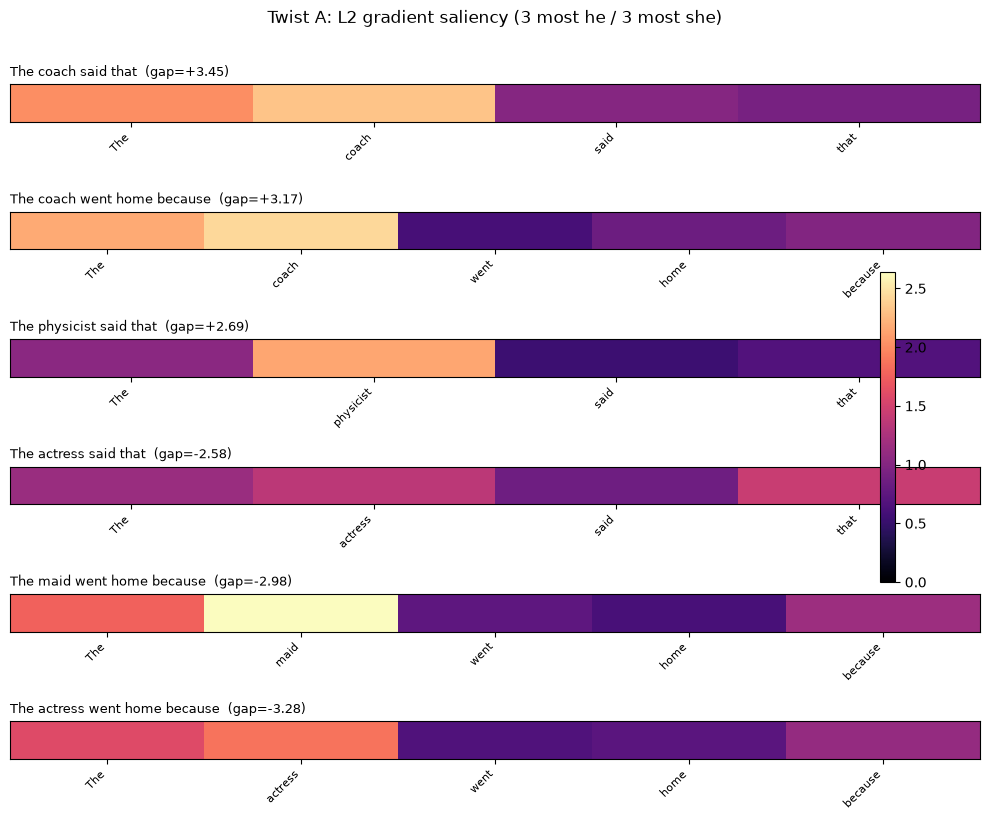

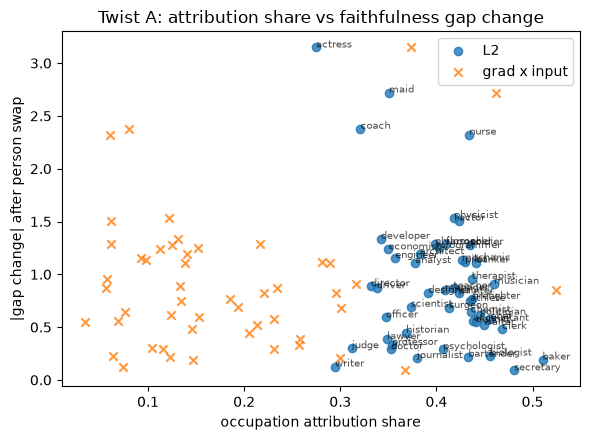

In [9]:
# Heatmap: 3 most he-leaning and 3 most she-leaning prompts (by gap)
ranked = sorted(example_sals, key=lambda t: t[1], reverse=True)
pick = ranked[:3] + ranked[-3:]
vmax = max(float(sal.max()) for *_, sal in pick)
fig, axes = plt.subplots(len(pick), 1, figsize=(10, 1.35 * len(pick)), squeeze=False)
for i, (prompt, gap, tokens, sal) in enumerate(pick):
    ax = axes[i, 0]
    im = ax.imshow(sal.numpy()[None, :], aspect="auto", cmap="magma", vmin=0, vmax=vmax)
    ax.set_yticks([])
    ax.set_xticks(range(len(tokens)))
    ax.set_xticklabels(tokens, rotation=45, ha="right", fontsize=8)
    ax.set_title(f"{prompt}  (gap={gap:+.2f})", fontsize=9, loc="left")
fig.colorbar(im, ax=axes.ravel().tolist(), fraction=0.02, pad=0.01)
fig.suptitle("Twist A: L2 gradient saliency (3 most he / 3 most she)", y=1.01)
plt.tight_layout()
plt.savefig(OUT_DIR / "twist_a_saliency_heatmap.png", dpi=120, bbox_inches="tight")
plt.show()

# Scatter: attribution share vs |gap change|
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(by_occ["attr_share_l2"], by_occ["abs_gap_change"], label="L2", alpha=0.8)
ax.scatter(by_occ["attr_share_gi"], by_occ["abs_gap_change"], label="grad x input", alpha=0.8, marker="x")
for _, r in by_occ.iterrows():
    ax.annotate(r["occupation"], (r["attr_share_l2"], r["abs_gap_change"]), fontsize=7, alpha=0.7)
ax.set_xlabel("occupation attribution share")
ax.set_ylabel("|gap change| after person swap")
ax.set_title("Twist A: attribution share vs faithfulness gap change")
ax.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / "twist_a_faithfulness_scatter.png", dpi=120)
plt.show()


**How to read Twist A (without peeking at numbers).**
A *faithful* result would show a clear positive Spearman link: occupations whose token gets a large attribution share are also the ones where swapping to ` person` moves the he−she gap a lot.
An *unfaithful* result would show little or no such link (or a negative one): the saliency lights up the occupation, but removing it barely changes the gap — or the reverse.


### Twist B — static embedding bias vs gradient saliency

Build a gender direction in GPT-2's input embeddings as the mean of several gendered difference vectors, then project each occupation embedding onto it (cosine similarity).
Compare that static score with (a) the he−she gap from Twist A and (b) the signed gradient × input saliency on the occupation token.


Spearman static_cos vs he-she gap:     rho=0.711, p=7.02e-09
Spearman static_cos vs signed gi_occ:  rho=-0.019, p=0.896
wrote outputs\twist_b_static_vs_saliency.csv


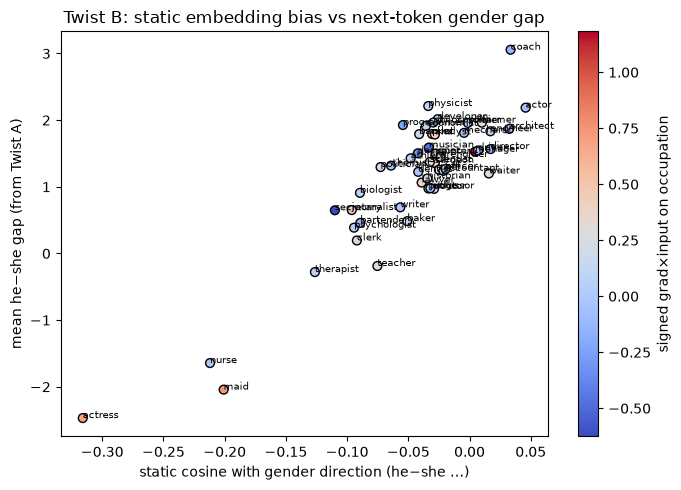

In [10]:
GENDER_PAIRS = [
    ("he", "she"), ("him", "her"), ("his", "her"), ("man", "woman"),
    ("men", "women"), ("boy", "girl"), ("father", "mother"), ("son", "daughter"),
]
wte = gpt2.transformer.wte.weight.detach()

def tok_vec(word: str):
    tid = tokenizer.encode(" " + word, add_special_tokens=False)
    assert len(tid) == 1, word
    return wte[tid[0]]

diffs = torch.stack([tok_vec(a) - tok_vec(b) for a, b in GENDER_PAIRS])
gender_dir = diffs.mean(0)
gender_dir = gender_dir / gender_dir.norm().clamp_min(1e-12)

rows_b = []
for occ in occupations:
    v = tok_vec(occ)
    static = float((v / v.norm().clamp_min(1e-12)) @ gender_dir)
    sub = by_occ.loc[by_occ["occupation"] == occ].iloc[0]
    rows_b.append({
        "occupation": occ,
        "static_cos": static,
        "gap": float(sub["gap"]),
        "signed_gi_occ": float(sub["signed_gi_occ"]),
    })

df_b = pd.DataFrame(rows_b)
rho_gap, p_gap = spearmanr(df_b["static_cos"], df_b["gap"])
rho_gi, p_gi_b = spearmanr(df_b["static_cos"], df_b["signed_gi_occ"])
print(f"Spearman static_cos vs he-she gap:     rho={rho_gap:.3f}, p={p_gap:.3g}")
print(f"Spearman static_cos vs signed gi_occ:  rho={rho_gi:.3f}, p={p_gi_b:.3g}")

df_b.to_csv(OUT_DIR / "twist_b_static_vs_saliency.csv", index=False)
print("wrote", OUT_DIR / "twist_b_static_vs_saliency.csv")

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df_b["static_cos"], df_b["gap"], c=df_b["signed_gi_occ"], cmap="coolwarm", edgecolors="k", s=40)
for _, r in df_b.iterrows():
    ax.annotate(r["occupation"], (r["static_cos"], r["gap"]), fontsize=7)
ax.set_xlabel("static cosine with gender direction (he−she …)")
ax.set_ylabel("mean he−she gap (from Twist A)")
ax.set_title("Twist B: static embedding bias vs next-token gender gap")
cbar = fig.colorbar(ax.collections[0], ax=ax)
cbar.set_label("signed grad×input on occupation")
plt.tight_layout()
plt.savefig(OUT_DIR / "twist_b_static_vs_gap.png", dpi=120)
plt.show()


**How to read Twist B (without peeking at numbers).**
A *faithful* alignment would mean occupations that sit toward "he" in the static embedding direction also show a higher he−she next-token gap, and the signed occupation saliency tends to agree in sign/rank.
An *unfaithful* result would mean the static projection and the model's next-token gap (or the gradient saliency) disagree — the embedding geometry and the contextual score point different ways.


## 5. Your findings

**Class models / saliency.** Class ascent images show coarse class texture; saliency usually lights the object more than the background.

**Twist A.** Occupation attribution share (L2 and grad×input) does **not** track the person-swap gap change (Spearman ≈ −0.23 / −0.10, n.s.) — saliency looks occupation-focused but fails this faithfulness check.

**Twist B.** Static embedding projection onto the gender direction **does** track the he−she next-token gap (ρ ≈ 0.71, p ≪ 0.001): nurse/maid/actress sit she-side, coach/engineer/doctor he-side. The same static score does **not** track signed grad×input on the occupation (ρ ≈ 0). So the bias is real and embedding-visible; gradient saliency on the occupation is not a reliable readout of it.

**Takeaway:** GPT-2’s occupation→pronoun bias aligns with static embedding geometry, but Simonyan-style input gradients are a weak explanation of that bias under a person-swap test.


## 6. Ideas for further exploration

- **Compare with occlusion maps (I001):** on the same images, compute Zeiler & Fergus occlusion sensitivity and measure agreement with these gradient saliency maps (for example Spearman rank correlation, or overlap of the top-k pixels).
- **SmoothGrad:** average saliency maps over many slightly noisy copies of the input and see whether the maps become sharper.
- **Gradient × input:** multiply the gradient by the input image itself and compare the result with raw gradient saliency.
- **VGG-16 vs ResNet-50:** run both visualisations with a second pretrained model and look at where the maps agree or differ.
- **Sanity check:** randomise the top-layer weights and see which maps barely change — a preview of Adebayo et al., *Sanity Checks for Saliency Maps* (2018, paper I013).
- **Class posteriors instead of scores:** the paper reports that maximising the softmax probability is less visually prominent. Try it and compare.
